| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_4_Integracion_numerica.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_1_Euler.ipynb) |

# 6.5 Diferenciación numérica: pendientes, errores y ruido

Una derivada expresa sensibilidad: cuánto cambia una salida cuando cambia una entrada. Si una función está disponible como un simulador, no siempre podemos derivarla simbólicamente. Las diferencias finitas aproximan derivadas mediante evaluaciones y también construyen operadores discretos de PDE.

Objetivos: derivar fórmulas hacia delante y centrales, observar el equilibrio entre truncamiento y redondeo, calcular segundas derivadas y jacobianos y entender el efecto del ruido. Los ejemplos utilizan NumPy, SciPy, Matplotlib y SymPy; no requieren una librería de aprendizaje profundo.

## 1. De un límite a una aproximación computable

La derivada es
$$f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.$$
En el ordenador $h$ no puede reducirse indefinidamente: $f(x+h)$ y $f(x)$ se representan con precisión finita. El paso tiene unidades de la variable de entrada; la derivada tiene unidades de salida/entrada.

Antes de aproximar, comprueba que el modelo sea derivable en el punto. Para $|x|$ en cero, diferencias hacia izquierda y derecha dan pendientes distintas y no existe derivada clásica. Una fórmula central devuelve cero por simetría, pero ese resultado no crea una derivada inexistente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate, integrate
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True,
                     "font.size": 11})
np.set_printoptions(precision=5, suppress=True)

## 2. Diferencia hacia delante y hacia atrás

Taylor alrededor de $x$ da
$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+O(h^3).$$
Restando $f(x)$ y dividiendo por $h$,
$$D_+f(x)=\frac{f(x+h)-f(x)}{h}=f'(x)+\frac h2 f''(x)+O(h^2).$$
La diferencia hacia atrás es $D_-f=[f(x)-f(x-h)]/h=f'(x)-hf''(x)/2+O(h^2)$. Ambas son de primer orden. En un extremo del dominio, una diferencia unilateral evita pedir datos fuera; no obstante, existen fórmulas unilaterales de órdenes superiores.

El ejemplo geométrico muestra la secante para el seno cerca de un punto interior.

Pendiente exacta: 0.7648421872844885 Aproximada: 0.617474182059361


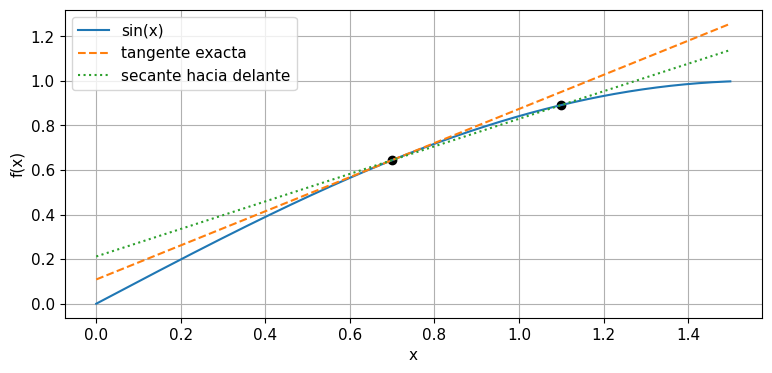

In [2]:
x0 = 0.7; h = 0.4
x = np.linspace(0, 1.5, 500)
forward = (np.sin(x0+h)-np.sin(x0))/h
plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.sin(x0)+np.cos(x0)*(x-x0), "--", label="tangente exacta")
plt.plot(x, np.sin(x0)+forward*(x-x0), ":", label="secante hacia delante")
plt.scatter([x0, x0+h], np.sin([x0, x0+h]), color="black")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.legend(); plt.show()
print("Pendiente exacta:", np.cos(x0), "Aproximada:", forward)

**Cómo interpretar el resultado.** La secante usa un intervalo finito y promedia cambios de pendiente. Al disminuir el paso debería acercarse a la tangente hasta que empiece a dominar la aritmética finita. Una gráfica de rectas muestra la geometría, pero no basta para elegir un paso óptimo.

## 3. Diferencia central y cancelación de términos

Restamos las expansiones de $f(x+h)$ y $f(x-h)$:
$$D_0f(x)=\frac{f(x+h)-f(x-h)}{2h}=f'(x)+\frac{h^2}{6}f^{(3)}(x)+O(h^4).$$
El término con $f''$ desaparece y el método alcanza orden dos. Si la función es exactamente un polinomio cuadrático, la derivada central es exacta en aritmética ideal. La simetría también exige acceso a ambos lados del punto.

La fórmula de cinco puntos
$$D_4f(x)=\frac{-f(x+2h)+8f(x+h)-8f(x-h)+f(x-2h)}{12h}$$
tiene error $O(h^4)$ para suficiente regularidad. Un orden mayor aumenta el número de evaluaciones y puede ser más sensible a ruido: precisión formal y robustez estadística son propiedades diferentes.

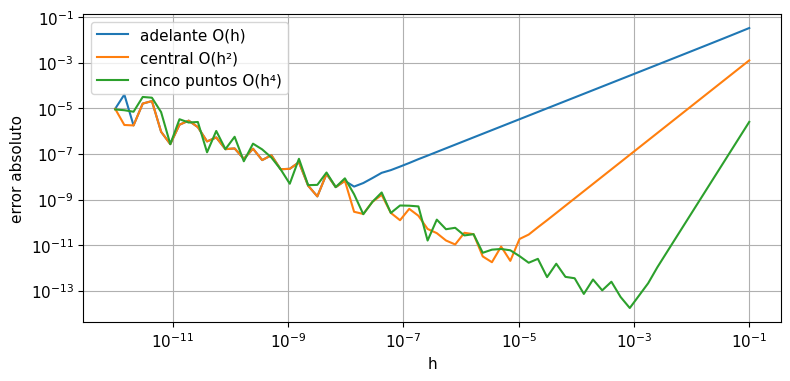

In [3]:
def forward_diff(fun, x, h): return (fun(x+h)-fun(x))/h
def central_diff(fun, x, h): return (fun(x+h)-fun(x-h))/(2*h)
def fourth_diff(fun, x, h):
    return (-fun(x+2*h)+8*fun(x+h)-8*fun(x-h)+fun(x-2*h))/(12*h)

hs = np.logspace(-1, -12, 70)
exact = np.cos(x0)
for name, method in [("adelante O(h)",forward_diff),
                     ("central O(h²)",central_diff),
                     ("cinco puntos O(h⁴)",fourth_diff)]:
    error = np.array([abs(method(np.sin,x0,h)-exact) for h in hs])
    plt.loglog(hs, np.maximum(error,1e-17), label=name)
plt.xlabel("h"); plt.ylabel("error absoluto"); plt.legend(); plt.show()

**Cómo interpretar el resultado.** La parte derecha, con pasos grandes, muestra las tasas de truncamiento. La parte izquierda, con pasos muy pequeños, suele mostrar aumento por cancelación y redondeo. El mínimo cambia con la función, el punto y la fórmula; no existe un único paso universal.

## 4. Truncamiento frente a redondeo

Un modelo útil del error es
$$E(h)\approx C_T h^p+C_R\frac{\varepsilon_{\rm mach}}h.$$
El primer término decrece al reducir el paso; el segundo crece porque la resta de valores cercanos pierde precisión y luego se divide entre $h$. Equilibrando ambos se obtiene una escala $h\sim\varepsilon_{\rm mach}^{1/(p+1)}$, con constantes y unidades que no deben ignorarse.

Para diferencias hacia delante aparece una escala $\sqrt\varepsilon$ y para centrales $\varepsilon^{1/3}$ en variables escaladas. Una política práctica utiliza $h_j=\eta\max(1,|x_j|)$ para variables adimensionales; si tienen escalas físicas distintas, define escalas por variable. Con simuladores aproximados, reemplaza el nivel de redondeo por el error real de evaluación.

In [4]:
eps = np.finfo(float).eps
print("Epsilon float64:", eps)
print("Escala adelante:", eps**0.5)
print("Escala central:", eps**(1/3))
print("¿1 + eps/4 es distinguible de 1?", 1 + eps/4 != 1)
for h in [1e-2, 1e-5, 1e-8, 1e-14, 1e-18]:
    print(f"h={h:.0e}, D+={forward_diff(np.exp,1.,h):.9f}")

Epsilon float64: 2.220446049250313e-16
Escala adelante: 1.4901161193847656e-08
Escala central: 6.055454452393343e-06
¿1 + eps/4 es distinguible de 1? False
h=1e-02, D+=2.731918656
h=1e-05, D+=2.718295420
h=1e-08, D+=2.718281822
h=1e-14, D+=2.708944180
h=1e-18, D+=0.000000000


**Cómo interpretar el resultado.** El último paso puede producir diferencia cero porque las entradas o salidas redondean al mismo número. La operación se ejecuta correctamente, pero la información necesaria para la derivada se perdió. Reducir el paso más allá de ese punto no corrige el problema.

## 5. Segunda derivada y operador de difusión

Sumando las expansiones simétricas,
$$D_{xx}f(x)=\frac{f(x+h)-2f(x)+f(x-h)}{h^2}
=f''(x)+\frac{h^2}{12}f^{(4)}(x)+O(h^4).$$
Esta fórmula construye el laplaciano 1D en la ecuación del calor. Su error de redondeo puede escalar como $\varepsilon/h^2$, más severo que para la primera derivada. Para $\sin x$, la segunda derivada exacta es $-\sin x$.

Sobre una malla, las posiciones interiores utilizan el stencil $[1,-2,1]/h^2$. En extremos hace falta información de frontera o un stencil unilateral; reutilizar indiscriminadamente el interior puede solicitar puntos inexistentes.

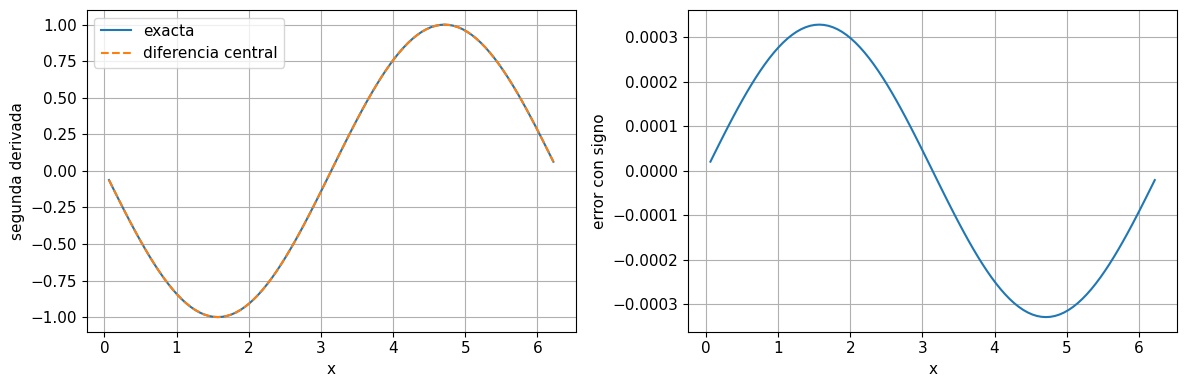

In [5]:
x = np.linspace(0, 2*np.pi, 101); h = x[1]-x[0]
y = np.sin(x)
d2 = (y[2:]-2*y[1:-1]+y[:-2])/h**2
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(x[1:-1], -np.sin(x[1:-1]), label="exacta")
ax[0].plot(x[1:-1], d2, "--", label="diferencia central")
ax[1].plot(x[1:-1], d2+np.sin(x[1:-1]))
ax[0].set(xlabel="x",ylabel="segunda derivada"); ax[0].legend()
ax[1].set(xlabel="x",ylabel="error con signo")
plt.tight_layout(); plt.show()

**Cómo interpretar el resultado.** El error tiene una estructura suave y ligada a las derivadas superiores del seno. No calculamos extremos para no imponer condiciones de frontera implícitas. En una PDE, esas condiciones deben definirse como parte del problema físico.

## 6. Datos discretos y ruido

Si cada observación contiene ruido independiente de varianza $\sigma^2$, la diferencia central tiene varianza
$$\operatorname{Var}(D_0\varepsilon)=\frac{2\sigma^2}{(2h)^2}=\frac{\sigma^2}{2h^2}.$$
Por tanto, muestrear más densamente sin reducir el ruido puede empeorar la derivada estimada. Un filtro polinómico local de Savitzky–Golay estima una tendencia suave en una ventana y permite derivarla. La ventana debe relacionarse con escalas físicas: una ventana demasiado grande borra cambios reales; demasiado pequeña conserva ruido.

`np.gradient` acepta la coordenada y puede manejar mallas no uniformes. Sus fórmulas de borde y sus supuestos deben revisarse; una derivada sobre datos no equivale a derivar una función exacta.

RMSE raw: 0.6321630121544887
RMSE filtrada: 0.04340766417680211


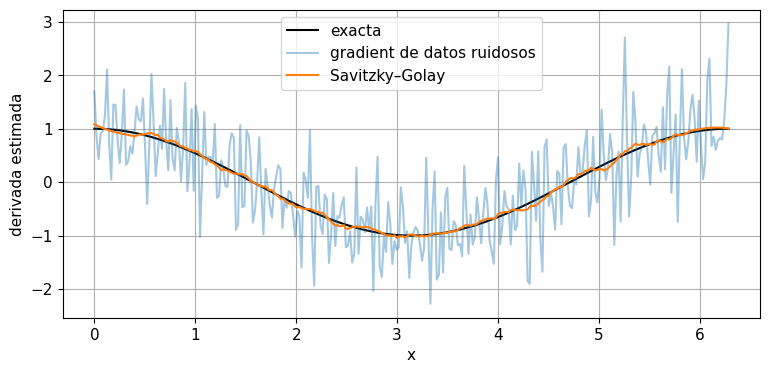

In [6]:
from scipy.signal import savgol_filter
rng = np.random.default_rng(7)
x = np.linspace(0, 2*np.pi, 301); h = x[1]-x[0]
y = np.sin(x)+rng.normal(0,0.02,x.size)
raw = np.gradient(y,x,edge_order=2)
smooth = savgol_filter(y,window_length=31,polyorder=3,deriv=1,delta=h)
plt.plot(x,np.cos(x),"k",label="exacta")
plt.plot(x,raw,alpha=0.4,label="gradient de datos ruidosos")
plt.plot(x,smooth,label="Savitzky–Golay")
plt.xlabel("x"); plt.ylabel("derivada estimada"); plt.legend(); plt.show()
interior = slice(15,-15)
print("RMSE raw:", np.sqrt(np.mean((raw[interior]-np.cos(x[interior]))**2)))
print("RMSE filtrada:", np.sqrt(np.mean((smooth[interior]-np.cos(x[interior]))**2)))

**Cómo interpretar el resultado.** Se mide el interior para separar el efecto de la ventana en los bordes. El filtro mejora este ejemplo porque la señal es suave y el ruido pequeño, pero puede sesgar una discontinuidad o un pico estrecho. Guarda siempre el ancho de ventana junto con el resultado.

## 7. Paso complejo para funciones analíticas

Para una función analítica que admite entradas complejas,
$$f(x+ih)=f(x)+ihf'(x)-\frac{h^2}{2}f''(x)+O(h^3),$$
y
$$f'(x)\approx\frac{\operatorname{Im}f(x+ih)}h.$$
No resta dos números reales cercanos, por lo que puede usar pasos muy pequeños. Requiere que toda la implementación preserve la extensión compleja. `abs`, comparaciones, recortes y rutinas que descartan partes imaginarias pueden invalidarlo. No debe aplicarse como truco universal a cualquier simulador.

Aquí $e^x$ admite esa extensión. Comparamos con una derivada simbólica para distinguir una aproximación numérica de una fórmula exacta.

In [7]:
import sympy as sp
z = sp.symbols("z")
symbolic = sp.diff(sp.exp(z),z)
print("Derivada simbólica:", symbolic)
for h in [1e-4,1e-8,1e-20]:
    approx = np.imag(np.exp(1+1j*h))/h
    print(f"h={h:.0e}, paso complejo={approx:.15f}, error={abs(approx-np.e):.3e}")

Derivada simbólica: exp(z)
h=1e-04, paso complejo=2.718281823928575, error=4.530e-09
h=1e-08, paso complejo=2.718281828459045, error=0.000e+00
h=1e-20, paso complejo=2.718281828459045, error=0.000e+00


**Cómo interpretar el resultado.** Los pasos muy pequeños pueden alcanzar precisión cercana a máquina para esta función. El resultado depende de una implementación compatible con números complejos; no demuestra que el mismo procedimiento funcione con lógica de control o funciones no analíticas.

## 8. Jacobiano de una función vectorial

Para $F:\mathbb R^d\to\mathbb R^m$, el jacobiano tiene entradas $J_{ij}=\partial F_i/\partial x_j$. La columna $j$ se estima perturbando solo la variable $j$:
$$J_{:,j}\approx\frac{F(x+h_je_j)-F(x-h_je_j)}{2h_j}.$$
Esto cuesta dos evaluaciones por variable, independientemente del número de salidas. Las unidades de cada columna pueden diferir. Un jacobiano puede servir para Newton, propagación de incertidumbre o sensitividades de un modelo.

Usamos $F(x_1,x_2)=(x_1^2+x_2,\sin(x_1x_2))$, cuyo jacobiano exacto es
$$\begin{pmatrix}2x_1&1\\x_2\cos(x_1x_2)&x_1\cos(x_1x_2)\end{pmatrix}.$$

In [8]:
def F(x):
    return np.array([x[0]**2+x[1], np.sin(x[0]*x[1])])

point = np.array([1.2,-0.7]); steps = 1e-5*np.maximum(1,abs(point))
J = np.empty((2,2))
for j in range(2):
    offset = np.zeros(2); offset[j] = steps[j]
    J[:,j] = (F(point+offset)-F(point-offset))/(2*steps[j])
co = np.cos(np.prod(point))
J_exact = np.array([[2*point[0],1.],[point[1]*co,point[0]*co]])
print("Jacobiano numérico:",J)
print("Jacobiano exacto:",J_exact)
print("Error máximo:",np.max(abs(J-J_exact)))

Jacobiano numérico: [[ 2.4      1.     ]
 [-0.46722  0.80096]]
Jacobiano exacto: [[ 2.4      1.     ]
 [-0.46722  0.80096]]
Error máximo: 2.3504753698944114e-11


**Cómo interpretar el resultado.** La comparación valida el orden de filas y columnas. Un error de orientación puede producir matrices de tamaño correcto pero sensitividades incorrectas. Repite con otra escala de variables para observar la importancia de pasos por componente.

## 9. Derivación automática y SciML

La diferenciación automática aplica la regla de la cadena a operaciones de un programa; no toma diferencias entre evaluaciones cercanas. Por eso no tiene un parámetro $h$ de diferencias finitas, aunque sí conserva redondeo y errores del programa diferenciado. La diferenciación simbólica genera expresiones analíticas y puede crecer mucho en complejidad.

En PINNs se suelen calcular derivadas de una red con autodiferenciación para formar un residual como $u_t-\alpha u_{xx}$. Una red suave puede derivarse con precisión mientras aproxima mal la solución: error de derivación y error de modelo son distintos. En física diferenciable, derivar el simulador discreto da la sensibilidad de esa discretización; comprobar refinamiento es necesario para relacionarla con la sensibilidad de la ecuación continua.

Las diferencias finitas sirven como control independiente de gradientes: compara productos $Jv$ con perturbaciones direccionales en varios tamaños de paso. Hazlo en puntos donde la función sea suave y sin decisiones discretas que cambien bajo perturbaciones.

## 10. Validación y límites

Comprueba primero una función con derivada conocida y después el problema real. Usa varios pasos y busca una región de estabilidad: un único resultado con $h=10^{-8}$ no es evidencia suficiente. Escala variables y evita evaluar fuera del dominio permitido. Comprueba si la función interna tiene tolerancias, iteraciones truncadas o aleatoriedad, pues esos errores se amplifican al dividir por $h$.

Con ruido aleatorio, repetir evaluaciones o utilizar números aleatorios comunes puede cambiar la varianza de una diferencia; debe describirse explícitamente. Para campos medidos, elige regularización según la resolución y el ruido, y valida con una señal o simulación de control. Si necesitas una segunda derivada, no supongas que derivar dos veces datos ruidosos es una operación inocua.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_4_Integracion_numerica.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_1_Euler.ipynb) |